# Research summary: multi-view mammography and clinical risk models
**Ayaz Mehmood** · MS Data Science (NUST) · [ayazmehmood550@gmail.com](mailto:ayazmehmood550@gmail.com)

This notebook summarises the experiments behind my three most recent manuscripts:

| # | Paper | Status | What it asks |
|---|---|---|---|
| 1 | *Intelligent Breast Cropping and Multi-View Fusion with Finding-BI-RADS Prototype Learning for Mammogram Classification* | IEEE Access, under review | Can one encoder read both views of a breast, and do clinically defined prototypes improve generalisation? |
| 2 | *Adaptive Foundation Model Learning for Breast-Level Classification from Dual-View Mammography* (MammoRLE-MIL) | ready for submission | How should a frozen DINOv2 model be adapted and pooled for dual-view mammography, and does it transfer? |
| 3 | *Machine Learning-Enabled Pre-Screening for Five-Year Risk of Common Cancers* | Cancer Epidemiology, submitted | Can routine primary-care data stratify cancer risk better than age alone? |

What runs here:
1. A re-implementation of the **boundary-aware breast cropping** used in paper 1, applied step by step to two sample mammograms.
2. The **result tables** of papers 1 and 2 (transcribed from the manuscripts), with charts of the main findings: internal vs external performance, ablations, efficiency.

The models themselves were trained on VinDr-Mammo, which is under a credentialed-access licence, so the training data and checkpoints are not included here.

In [1]:
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
import cv2

INK, MUTED, RULE = "#1e1e1e", "#6b6b6b", "#d9d6cf"
BLUE, ORANGE, GREEN, GREY = "#1a4d8f", "#c0612b", "#3a7d44", "#9a9a9a"
mpl.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Serif", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": RULE,
    "axes.grid": True, "grid.color": "#eeece6", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "xtick.color": MUTED, "ytick.color": MUTED})
pd.set_option("display.precision", 3)

## 1 · Paper 1: cropping, merged views and Finding-BI-RADS prototypes

**Pipeline.** Each mammogram is cropped to the breast; the MLO view is flipped so that the chest walls of both views meet in the middle; the two crops are concatenated into one composite and passed through **a single encoder** (EfficientNet-B3 or ConvNeXt-Base). During training, two prototype memories (one for radiological *finding types*, one for *BI-RADS categories*) pull embeddings towards clinically meaningful anchors. The prototypes are used only during training, so they add nothing at inference.

Tasks: binary normal (BI-RADS 1) vs abnormal (BI-RADS 2–5), and five-class BI-RADS grading with an ordinal (CORAL-style) head. Trained on **VinDr-Mammo**, tested externally on **INbreast** without fine-tuning.

### 1.1 Boundary-aware cropping, re-implemented
The steps follow the paper: Gaussian smoothing → Otsu threshold → 5×5 morphological closing/opening → largest connected component → a **row-wise tissue-extent profile**. Starting from the widest row, the profile is followed up and down while the breast keeps tapering. Where it stops tapering (pectoral muscle, skin folds, artefacts), the crop boundary is placed, with a margin. The crop uses no lesion annotations.

In [2]:
from dataclasses import dataclass

import cv2
import numpy as np


@dataclass
class CropResult:
    image: np.ndarray        # cropped image
    mask: np.ndarray         # breast mask (full size)
    otsu: np.ndarray         # raw Otsu mask (full size)
    profile: np.ndarray      # row-wise tissue extent (pixels)
    ref_row: int             # widest row
    box: tuple               # (x0, y0, x1, y1) in original coordinates
    laterality: str          # 'L' (chest wall on the left) or 'R'


def breast_mask(img, blur=5, kernel=5):
    g = cv2.GaussianBlur(img, (blur, blur), 0)
    _, otsu = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    m = cv2.morphologyEx(otsu, cv2.MORPH_CLOSE, k)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1:
        return otsu > 0, m > 0
    largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return otsu > 0, lab == largest


def _walk(profile, start, step, tol):
    """Follow the profile from `start` while the extent keeps decreasing."""
    i = start
    while 0 <= i + step < len(profile):
        nxt = profile[i + step]
        if nxt == 0:                       # left the breast
            return i
        if nxt > profile[i] + tol:         # extent widens again -> other structure
            return i
        i += step
    return i


def crop_breast(img, view="CC", margin_frac=0.03, tol_frac=0.004):
    """Return a CropResult for a single grayscale mammogram (uint8)."""
    h, w = img.shape
    otsu, mask = breast_mask(img)
    cols = np.where(mask.any(0))[0]
    x0, x1 = int(cols.min()), int(cols.max())
    # chest wall is on the side where the mask touches the image border
    laterality = "L" if mask[:, : w // 10].sum() > mask[:, -w // 10:].sum() else "R"

    profile = mask.sum(1).astype(int)
    ref = int(np.argmax(profile))
    tol = max(1, int(tol_frac * w))
    top = _walk(profile, ref, -1, tol)
    bot = _walk(profile, ref, +1, tol)

    # adaptive margin (paper: 50-100 px at full resolution); relaxed for MLO
    m = int(margin_frac * h * (1.6 if view.upper() == "MLO" else 1.0))
    pad = int(0.02 * w)
    y0, y1 = max(0, top - m), min(h, bot + m)
    if laterality == "L":
        x0, x1 = max(0, x0 - pad), min(w, x1 + m)
    else:
        x0, x1 = max(0, x0 - m), min(w, x1 + pad)
    crop = img[y0:y1, x0:x1]
    return CropResult(crop, mask, otsu, profile, ref, (x0, y0, x1, y1), laterality)


def merge_views(cc, mlo, cc_lat, mlo_lat, size=512):
    """Flip so both chest walls meet in the centre, pad to equal height, concat, resize."""
    # CC on the left with chest wall on its right; MLO on the right with chest wall on its left
    if cc_lat == "L":
        cc = cv2.flip(cc, 1)
    if mlo_lat == "R":
        mlo = cv2.flip(mlo, 1)
    hmax = max(cc.shape[0], mlo.shape[0])

    def pad(x):
        d = hmax - x.shape[0]
        return cv2.copyMakeBorder(x, d // 2, d - d // 2, 0, 0, cv2.BORDER_CONSTANT, value=0)

    comp = np.hstack([pad(cc), pad(mlo)])
    return cv2.resize(comp, (size, size), interpolation=cv2.INTER_CUBIC), comp

Right CC: laterality=R, box=(237, 0, 511, 477), kept 40% of pixels
Left CC: laterality=L, box=(0, 0, 289, 514), kept 45% of pixels


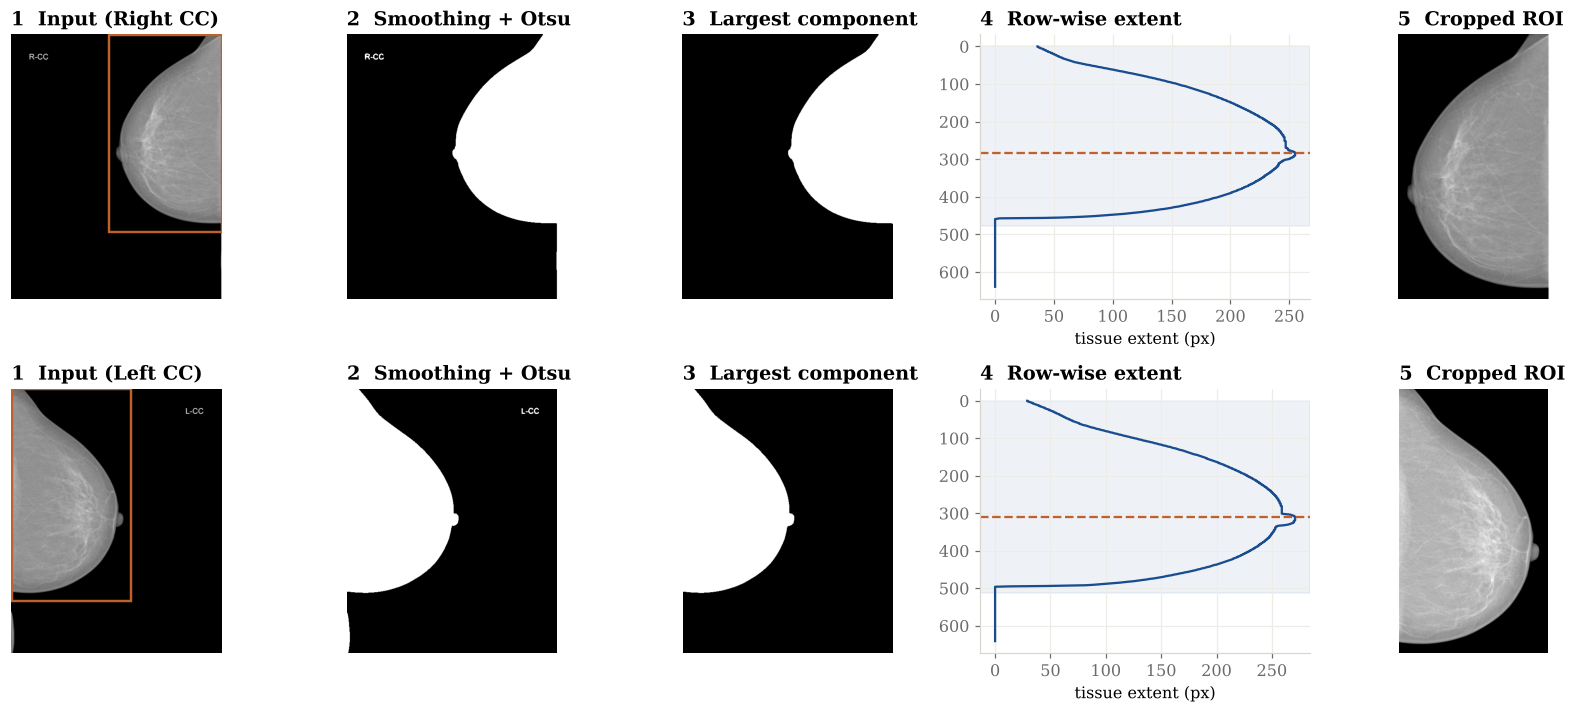

In [3]:
DATA = next((p for p in [Path("data"), Path("/kaggle/input/mammo-samples")] if (p / "sample_view_a.png").exists()), None)
if DATA is None:
    print("Sample images not found: put sample_view_a.png / sample_view_b.png in ./data")
else:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.15, 0.8]})
    for row, (name, label) in enumerate([("sample_view_a.png", "Right CC"), ("sample_view_b.png", "Left CC")]):
        img = cv2.imread(str(DATA / name), 0)
        r = crop_breast(img)
        x0, y0, x1, y1 = r.box
        ax = axes[row]
        ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"1  Input ({label})")
        ax[0].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=ORANGE, lw=1.6))
        ax[1].imshow(r.otsu, cmap="gray"); ax[1].set_title("2  Smoothing + Otsu")
        ax[2].imshow(r.mask, cmap="gray"); ax[2].set_title("3  Largest component")
        ax[3].plot(r.profile, np.arange(len(r.profile)), color=BLUE); ax[3].invert_yaxis()
        ax[3].axhline(r.ref_row, color=ORANGE, ls="--"); ax[3].axhspan(y0, y1, color=BLUE, alpha=.07)
        ax[3].set_title("4  Row-wise extent"); ax[3].set_xlabel("tissue extent (px)")
        ax[4].imshow(r.image, cmap="gray"); ax[4].set_title("5  Cropped ROI")
        for a in (ax[0], ax[1], ax[2], ax[4]):
            a.axis("off")
        print(f"{label}: laterality={r.laterality}, box={r.box}, kept {100*r.image.size/img.size:.0f}% of pixels")
    plt.tight_layout(); plt.show()

In the paper, every annotated lesion box in VinDr-Mammo was mapped through this crop to check that no diagnostic tissue is lost:

In [4]:
crop_check = pd.DataFrame({"lesion boxes": [2254], "fully inside crop": [2239], "partly cut": [9], "outside crop": [6]})
crop_check["% fully kept"] = 100 * crop_check["fully inside crop"] / crop_check["lesion boxes"]
crop_check

,lesion boxes,fully inside crop,partly cut,outside crop,% fully kept
0,2254,2239,9,6,99.335


### 1.2 Results

In [5]:
# --- Paper 1: Cropping + merged view + Finding-BI-RADS prototypes (IEEE Access, under review)
# (VinDr F1, VinDr AUC, INbreast F1, INbreast AUC), binary task, 512 px
IEEE_BINARY_MERGED = {
    "EfficientNet-B3": {"Merged": (0.7671, 0.8158, 0.6577, 0.8705), "M+BF": (0.7812, 0.8268, 0.7531, 0.9087),
                        "Merged 1024px": (0.7980, 0.8664, 0.6623, 0.9117)},
    "ConvNeXt-Base": {"Merged": (0.7889, 0.8569, 0.7107, 0.9100), "M+BF": (0.8009, 0.8615, 0.7584, 0.9170),
                      "Merged 1024px": (0.8104, 0.8853, 0.7197, 0.9291)},
}
IEEE_BINARY_TWOVIEW = {
    "EfficientNet-B3": {"256": (0.6845, 0.7349, 0.6038, 0.8408), "512": (0.7807, 0.8304, 0.6569, 0.9155)},
    "ConvNeXt-Base": {"256": (0.7615, 0.8092, 0.6005, 0.8711), "512": (0.8045, 0.8786, 0.6958, 0.9019)},
}
IEEE_FIVECLASS_MERGED = {
    "EfficientNet-B3": {"Merged": (0.4663, 0.7855, 0.4117, 0.7860), "M+BF": (0.5379, 0.8079, 0.5182, 0.8063)},
    "ConvNeXt-Base": {"Merged": (0.5165, 0.8026, 0.5157, 0.8278), "M+BF": (0.5493, 0.8062, 0.5403, 0.8325)},
}
# (QWK VinDr, MAE VinDr, QWK INbreast, MAE INbreast)
IEEE_ORDINAL = {
    "EfficientNet-B3": {"Merged": (0.601, 0.301, 0.682, 0.587), "M+BF": (0.637, 0.276, 0.694, 0.572)},
    "ConvNeXt-Base": {"Merged": (0.643, 0.275, 0.738, 0.552), "M+BF": (0.665, 0.271, 0.784, 0.497)},
}
# Ablation, ConvNeXt-Base binary macro-F1 (VinDr, INbreast)
IEEE_ABLATION_BIN = [
    ("Single view (CC only)", 0.7706, 0.6507),
    ("Merged, no cropping", 0.7760, 0.6520),
    ("Dual encoder", 0.8045, 0.6958),
    ("Dual encoder, shared weights", 0.7979, 0.7279),
    ("Merged view", 0.7889, 0.7107),
    ("+ finding prototypes", 0.8010, 0.7449),
    ("+ BI-RADS prototypes", 0.7922, 0.6956),
    ("+ both (M+BF, proposed)", 0.8009, 0.7584),
    ("M+BF, MLO masked at test", 0.7355, 0.6430),
]
# Params (M), GFLOPs, latency ms, throughput breasts/s
IEEE_EFFICIENCY = {
    "EfficientNet-B3": {"Two-View": (22.2, 20.1, 26.2, 117.8), "Shared Two-View": (11.5, 20.1, 12.9, 119.6), "Merged": (11.1, 10.0, 12.3, 520.8)},
    "ConvNeXt-Base": {"Two-View": (175.7, 320.9, 24.4, 44.9), "Shared Two-View": (88.1, 320.9, 29.7, 45.4), "Merged": (87.8, 160.4, 9.5, 193.8)},
}
IEEE_CROP_CHECK = {"boxes": 2254, "fully_kept": 2239, "partial": 9, "outside": 6}

# --- Paper 2: MammoRLE-MIL (DINOv2 + routed low-rank experts + multi-head MIL)
# id -> name, dataset -> (AUC, AP)
FM_CROSS = {
    "E1": {"name": "global mean", "VinDr-Mammo": (0.773, 0.427), "INbreast": (0.726, 0.548), "LUMINA": (0.647, 0.645)},
    "E2": {"name": "ABMIL", "VinDr-Mammo": (0.845, 0.571), "INbreast": (0.855, 0.785), "LUMINA": (0.729, 0.751)},
    "E3": {"name": "MH-MIL-2", "VinDr-Mammo": (0.855, 0.580), "INbreast": (0.876, 0.814), "LUMINA": (0.710, 0.736)},
    "E4": {"name": "MoLRE-3+ABMIL", "VinDr-Mammo": (0.878, 0.606), "INbreast": (0.868, 0.803), "LUMINA": (0.709, 0.737)},
    "E5": {"name": "MoLRE-3+MH-2", "VinDr-Mammo": (0.860, 0.582), "INbreast": (0.844, 0.764), "LUMINA": (0.752, 0.769)},
    "E6": {"name": "MoLRE-2+MH-2", "VinDr-Mammo": (0.866, 0.590), "INbreast": (0.865, 0.784), "LUMINA": (0.722, 0.751)},
    "E7": {"name": "MoLRE-4+MH-2", "VinDr-Mammo": (0.846, 0.571), "INbreast": (0.859, 0.796), "LUMINA": (0.748, 0.768)},
    "E8": {"name": "MoLRE-3+MH-3", "VinDr-Mammo": (0.870, 0.608), "INbreast": (0.873, 0.814), "LUMINA": (0.715, 0.743)},
}

In [6]:
rows = []
for bb, d in IEEE_BINARY_TWOVIEW.items():
    rows.append((bb, "Two-view (dual encoder)", "512", *d["512"]))
for bb, d in IEEE_BINARY_MERGED.items():
    rows.append((bb, "Merged view", "512", *d["Merged"]))
    rows.append((bb, "Merged view", "1024", *d["Merged 1024px"]))
    rows.append((bb, "Merged + prototypes (M+BF)", "512", *d["M+BF"]))
binary = pd.DataFrame(rows, columns=["Backbone", "Configuration", "Res.", "VinDr F1", "VinDr AUC", "INbreast F1", "INbreast AUC"])
binary.style.format(precision=3).set_caption("Binary normal vs abnormal (macro-F1, AUC)")

,Backbone,Configuration,Res.,VinDr F1,VinDr AUC,INbreast F1,INbreast AUC
0,EfficientNet-B3,Two-view (dual encoder),512,0.781,0.830,0.657,0.915
1,ConvNeXt-Base,Two-view (dual encoder),512,0.804,0.879,0.696,0.902
2,EfficientNet-B3,Merged view,512,0.767,0.816,0.658,0.871
3,EfficientNet-B3,Merged view,1024,0.798,0.866,0.662,0.912
4,EfficientNet-B3,Merged + prototypes (M+BF),512,0.781,0.827,0.753,0.909
5,ConvNeXt-Base,Merged view,512,0.789,0.857,0.711,0.910
6,ConvNeXt-Base,Merged view,1024,0.810,0.885,0.720,0.929
7,ConvNeXt-Base,Merged + prototypes (M+BF),512,0.801,0.862,0.758,0.917


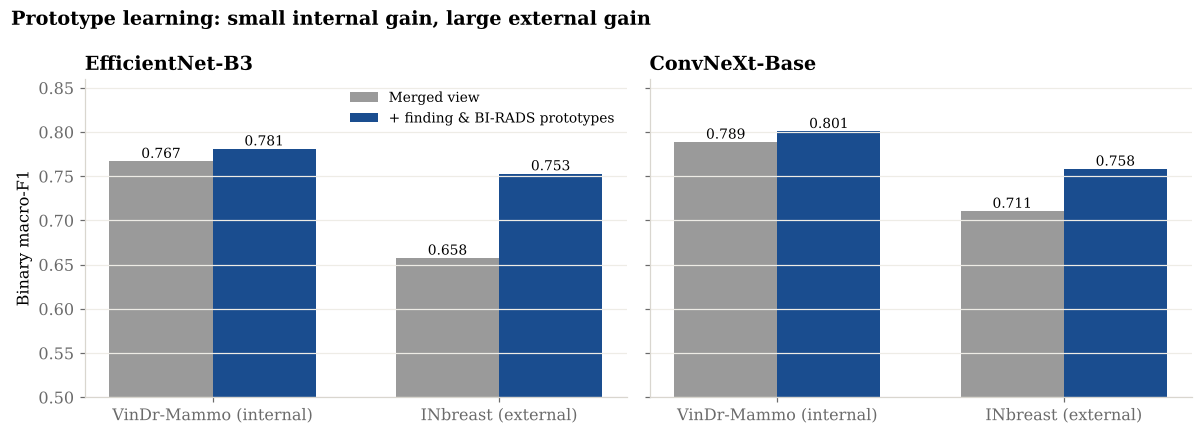

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, bb in zip(axes, IEEE_BINARY_MERGED):
    d = IEEE_BINARY_MERGED[bb]; x = np.arange(2); w = .36
    for off, key, col, lab in [(-w/2, "Merged", GREY, "Merged view"), (w/2, "M+BF", BLUE, "+ finding & BI-RADS prototypes")]:
        bars = ax.bar(x + off, [d[key][0], d[key][2]], w, color=col, label=lab)
        ax.bar_label(bars, fmt="%.3f", fontsize=9)
    ax.set_xticks(x, ["VinDr-Mammo (internal)", "INbreast (external)"]); ax.set_title(bb); ax.set_ylim(.5, .86); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Binary macro-F1"); axes[0].legend(fontsize=9)
plt.suptitle("Prototype learning: small internal gain, large external gain", x=.01, ha="left", fontweight="bold"); plt.tight_layout(); plt.show()

In [8]:
rows = []
for bb in IEEE_FIVECLASS_MERGED:
    for cfg in ("Merged", "M+BF"):
        f = IEEE_FIVECLASS_MERGED[bb][cfg]; o = IEEE_ORDINAL[bb][cfg]
        rows.append((bb, cfg, f[0], f[1], o[0], o[1], f[2], f[3], o[2], o[3]))
five = pd.DataFrame(rows, columns=["Backbone", "Config", "VinDr F1", "VinDr AUC", "VinDr QWK", "VinDr MAE",
                                   "INbreast F1", "INbreast AUC", "INbreast QWK", "INbreast MAE"])
five.style.format(precision=3).set_caption("Five-class BI-RADS grading (512 px)")

,Backbone,Config,VinDr F1,VinDr AUC,VinDr QWK,VinDr MAE,INbreast F1,INbreast AUC,INbreast QWK,INbreast MAE
0,EfficientNet-B3,Merged,0.466,0.785,0.601,0.301,0.412,0.786,0.682,0.587
1,EfficientNet-B3,M+BF,0.538,0.808,0.637,0.276,0.518,0.806,0.694,0.572
2,ConvNeXt-Base,Merged,0.516,0.803,0.643,0.275,0.516,0.828,0.738,0.552
3,ConvNeXt-Base,M+BF,0.549,0.806,0.665,0.271,0.540,0.833,0.784,0.497


In [9]:
abl = pd.DataFrame(IEEE_ABLATION_BIN, columns=["Variant (ConvNeXt-Base, binary)", "VinDr F1", "INbreast F1"])
abl["gap (internal - external)"] = abl["VinDr F1"] - abl["INbreast F1"]
abl.style.format(precision=3).background_gradient(subset=["INbreast F1"], cmap="Blues")

,"Variant (ConvNeXt-Base, binary)",VinDr F1,INbreast F1,gap (internal - external)
0,Single view (CC only),0.771,0.651,0.120
1,"Merged, no cropping",0.776,0.652,0.124
2,Dual encoder,0.804,0.696,0.109
3,"Dual encoder, shared weights",0.798,0.728,0.070
4,Merged view,0.789,0.711,0.078
5,+ finding prototypes,0.801,0.745,0.056
6,+ BI-RADS prototypes,0.792,0.696,0.097
7,"+ both (M+BF, proposed)",0.801,0.758,0.042
8,"M+BF, MLO masked at test",0.736,0.643,0.093


In [10]:
eff = pd.DataFrame([(bb, cfg, *v) for bb, d in IEEE_EFFICIENCY.items() for cfg, v in d.items()],
                   columns=["Backbone", "Configuration", "Params (M)", "GFLOPs", "Latency (ms)", "Throughput (breasts/s)"])
eff

,Backbone,Configuration,Params (M),GFLOPs,Latency (ms),Throughput (breasts/s)
0,EfficientNet-B3,Two-View,22.2,20.1,26.2,117.8
1,EfficientNet-B3,Shared Two-View,11.5,20.1,12.9,119.6
2,EfficientNet-B3,Merged,11.1,10.0,12.3,520.8
3,ConvNeXt-Base,Two-View,175.7,320.9,24.4,44.9
4,ConvNeXt-Base,Shared Two-View,88.1,320.9,29.7,45.4
5,ConvNeXt-Base,Merged,87.8,160.4,9.5,193.8


**Take-aways from paper 1**
- One encoder on a merged CC+MLO composite matches a parameter-matched shared two-view encoder, with **half the FLOPs and about 4× the throughput**.
- Cropping helps (removing it lowers F1 for both backbones), and 99.3% of lesion boxes stay fully inside the crop.
- Finding + BI-RADS prototypes give a modest internal gain but a **large external gain** (INbreast binary F1 +0.095 for EfficientNet-B3). The gain is significant on McNemar's test (p < 0.01) for all four model–dataset pairs, and larger than the seed-to-seed spread (SD 0.006).
- Where it still fails: BI-RADS 3 and 4 recall (0.16–0.40), dense breasts, and the Planmed device. These are reported per subgroup with 95% CIs in the paper.

## 2 · Paper 2: MammoRLE-MIL, adapting DINOv2 to dual-view mammography

A frozen **DINOv2 ViT-B/14** encodes each view at 518×518 (1,369 patch tokens). Two components are added and ablated:
- **MoLRE (mixture of low-rank experts):** K LoRA experts on the query and value projections, mixed per image by a small router. The backbone stays frozen, and the zero-initialised experts start out as the original model.
- **Multi-head gated-attention MIL:** several attention heads pool the patch tokens of each view; their outputs are weighted and fused. CC and MLO embeddings are concatenated for one breast-level prediction.

Eight configurations (E1–E8) were trained on VinDr-Mammo and tested on INbreast (same BI-RADS label definition) and LUMINA (multi-vendor, pathology labels), without any fine-tuning on the external sets.

In [11]:
ids = list(FM_CROSS)
fm = pd.DataFrame([(e, FM_CROSS[e]["name"], *[v for ds in ("VinDr-Mammo", "INbreast", "LUMINA") for v in FM_CROSS[e][ds]]) for e in ids],
                  columns=["ID", "Configuration", "VinDr AUC", "VinDr AP", "INbreast AUC", "INbreast AP", "LUMINA AUC", "LUMINA AP"])
fm.style.format(precision=3).highlight_max(subset=fm.columns[2:], color="#dbe6f4")

,ID,Configuration,VinDr AUC,VinDr AP,INbreast AUC,INbreast AP,LUMINA AUC,LUMINA AP
0,E1,global mean,0.773,0.427,0.726,0.548,0.647,0.645
1,E2,ABMIL,0.845,0.571,0.855,0.785,0.729,0.751
2,E3,MH-MIL-2,0.855,0.580,0.876,0.814,0.710,0.736
3,E4,MoLRE-3+ABMIL,0.878,0.606,0.868,0.803,0.709,0.737
4,E5,MoLRE-3+MH-2,0.860,0.582,0.844,0.764,0.752,0.769
5,E6,MoLRE-2+MH-2,0.866,0.590,0.865,0.784,0.722,0.751
6,E7,MoLRE-4+MH-2,0.846,0.571,0.859,0.796,0.748,0.768
7,E8,MoLRE-3+MH-3,0.870,0.608,0.873,0.814,0.715,0.743


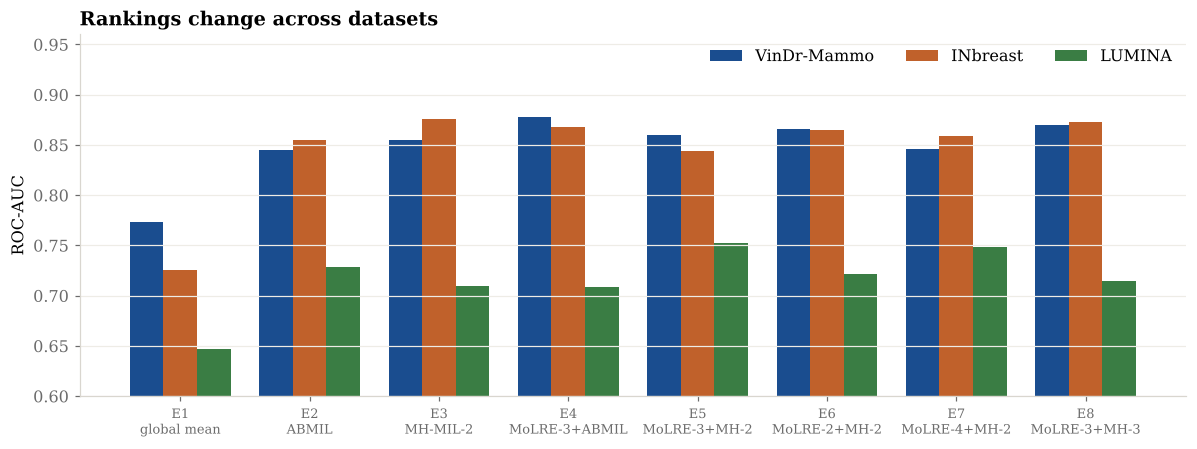

Rank of each configuration per dataset (1 = best):


ID,E1,E2,E3,E4,E5,E6,E7,E8
VinDr AUC,8,7,5,1,4,3,6,2
INbreast AUC,8,6,1,3,7,4,5,2
LUMINA AUC,8,3,6,7,1,4,2,5


In [12]:
fig, ax = plt.subplots(figsize=(11, 4.2)); x = np.arange(len(ids)); w = .26
for i, (ds, col) in enumerate(zip(["VinDr-Mammo", "INbreast", "LUMINA"], [BLUE, ORANGE, GREEN])):
    ax.bar(x + (i - 1) * w, [FM_CROSS[e][ds][0] for e in ids], w, color=col, label=ds)
ax.set_xticks(x, [f"{e}\n{FM_CROSS[e]['name']}" for e in ids], fontsize=8.5); ax.set_ylim(.6, .96)
ax.set_ylabel("ROC-AUC"); ax.legend(ncol=3); ax.grid(axis="x", visible=False)
ax.set_title("Rankings change across datasets"); plt.tight_layout(); plt.show()

rank = fm.set_index("ID")[["VinDr AUC", "INbreast AUC", "LUMINA AUC"]].rank(ascending=False).astype(int)
print("Rank of each configuration per dataset (1 = best):"); rank.T

**Take-aways from paper 2**
- The biggest single step is replacing global mean pooling with attention MIL (+0.072 AUC, +0.143 AP on VinDr). All MIL and MoLRE variants beat the frozen baseline (DeLong p < 0.001).
- MoLRE adds a further gain at fixed pooling (E2 → E4: +0.033 AUC, p = 0.014). The best internal AUC is **0.878**, and the best INbreast AP is **0.814**.
- More experts or more heads is **not** monotonically better, and the best configuration differs between VinDr, INbreast and LUMINA. LUMINA changes both the domain and the label (pathology rather than BI-RADS), so this is reported as a trade-off rather than one winning model.

## 3 · Paper 3: five-year cancer risk from routine data (brief)
Developed at Klarity with UK Biobank data. Machine-learning models predict five-year incidence of six common cancers from demographic and clinical variables, as a pre-screening step before invitation. Compared with age-based invitation, the high-risk group is enriched about three-fold. The details stay with the manuscript while it is under review.

## 4 · What I'm working on now
- **Cross-device harmonisation** of mammograms before classification. This follows from the device-level drops found in papers 1 and 2.
- **Device unlearning**, to measure how much vendor-specific information the learned representations retain.
- **H&E → IHC virtual staining** with flow matching. An earlier attempt at lesion synthesis with LoRA-adapted latent-diffusion inpainting did not help downstream performance, which is what motivated the switch.